In [1]:
rm(list = ls(all.names = TRUE)) # will clear all objects including hidden objects
gc() # free up memory and report the memory usage
options(max.print = .Machine$integer.max, scipen = 999, stringsAsFactors = F, dplyr.summarise.inform = F) # avoid truncated output in R console and scientific notation

,used,(Mb),gc trigger,(Mb),max used,(Mb)
Ncells,627368,33.6,1360335,72.7,1176793,62.9
Vcells,1165394,8.9,8388608,64.0,1801376,13.8


In [2]:
# Loading relevant libraries 
library(tidyverse) # includes ggplot2, for data visualisation. dplyr, for data manipulation.
library(Seurat)
library(Signac)
library(scDblFinder)
options(repr.plot.width=10, repr.plot.height=8)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.4     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Attaching SeuratObject

Seurat v4 was just loaded with SeuratObject v5; disabling v5 assays and
validation routines, and ensuring assays work in strict v3/v4
compatibility mode

Signac built for for SeuratObject v4 was just loaded with SeuratObject
v5; disabling v5 assays and validation routines, and ensuring assays
work in strict v3/v4 compatibility mode

Loading required package: SingleCellExperiment

Loading required package: SummarizedExperiment

Loading required pack

In [3]:
# Relevant paths ======================================================================
project_path <- "~/cluster/projects/u19_multiomics/analyses"
in_path <- file.path(project_path, 'remove_dup/data')
out_path <- file.path(project_path, 'scRNA_duplets/results') # for all scRNAseq preprocessing results
doublet_folder <- file.path(out_path, 'scRNA_duplets/Doublet_detection') # subfolder for Doublet detection results
#dir.create(doublet_folder, recursive = TRUE, showWarnings = FALSE) 

In [4]:
# Inputs ======================================================================
# Read in your Seurat object
seu <- readRDS(file.path(in_path, "lungs_spleens_processed.rds"))
head(seu@meta.data)

,orig.ident,nCount_RNA,nFeature_RNA,percent.mt,nCount_ATAC,nFeature_ATAC,integrated_snn_res.0.5,seurat_clusters,immune_low,lung_atlas,tissue.ident,full.ident,nCount_peaks,nFeature_peaks,majority_voting,merged
,<chr>,<dbl>,<int>,<dbl>,<dbl>,<int>,<fct>,<fct>,<chr>,<chr>,<chr>,<chr>,<dbl>,<int>,<chr>,<chr>
AAACAGCCAACAACAA-2_1,2,4891,2351,1.819669,20272,8234,8,8,Memory B cells,B cells,lungs,lungs_2,11791,8456,Memory B cells,Memory B cells
AAACAGCCACAGCCTG-2_1,2,2106,1225,4.415954,7866,3694,1,1,CD16+ NK cells,NK cells,lungs,lungs_2,4511,3829,CD16+ NK cells,CD16+ NK cells
AAACAGCCAGGATGGC-2_1,2,2503,1303,3.995206,8074,3733,0,0,Tcm/Naive helper T cells,CD4 T cells,lungs,lungs_2,4668,3890,Tcm/Naive helper T cells,T cells
AAACAGCCATCAGTAT-2_1,2,3573,1591,4.114190,19628,8126,0,0,Tcm/Naive helper T cells,CD4 T cells,lungs,lungs_2,11343,8194,Tcm/Naive helper T cells,T cells
AAACAGCCATGAAGTA-2_1,2,6324,2584,1.391524,856,451,2,2,Tem/Trm cytotoxic T cells,CD8 T cells,lungs,lungs_2,485,478,Tem/Trm cytotoxic T cells,T cells
AAACAGCCATTAAACC-2_1,2,3075,1388,4.715447,10015,4639,7,7,Type 17 helper T cells,CD4 T cells,lungs,lungs_2,5740,4795,Type 17 helper T cells,T cells


In [5]:
rnameta <- readRDS("../output/rna_meta_doublet_detected.RDS")
seu@meta.data$scDblFinder.class <- rnameta$scDblFinder.class

In [6]:
library(data.table)
joint_meta <- fread("../output/rna_metadata.txt")
seu@meta.data$PredCellType <- joint_meta$PredCellType


Attaching package: ‘data.table’


The following object is masked from ‘package:SummarizedExperiment’:

    shift


The following object is masked from ‘package:GenomicRanges’:

    shift


The following object is masked from ‘package:IRanges’:

    shift


The following objects are masked from ‘package:S4Vectors’:

    first, second


The following objects are masked from ‘package:lubridate’:

    hour, isoweek, mday, minute, month, quarter, second, wday, week,
    yday, year


The following objects are masked from ‘package:dplyr’:

    between, first, last


The following object is masked from ‘package:purrr’:

    transpose




In [21]:
rm(sce)
rm(seu)

In [7]:
# Doublet detection =================================================================

## scDblFinder -------------------------------
# Run scDbltFinder
sce <- as.SingleCellExperiment(seu)

Warning message in .check_reddim_names(x, value, withDimnames):
“non-NULL 'rownames(value)' should be the same as 'colnames(x)' for
'reducedDim<-'. This will be an error in the next release of
Bioconductor.”


In [8]:
sce <- as.SingleCellExperiment(seu)
sce <- scDblFinder(sce, samples = "full.ident") #dbr = multiplet_rate)
table(sce$scDblFinder.class)
sce@colData@listData %>% as.data.frame() %>% head()


singlet doublet 
  48942    4705 

,orig.ident,nCount_RNA,nFeature_RNA,percent.mt,nCount_ATAC,nFeature_ATAC,integrated_snn_res.0.5,seurat_clusters,immune_low,lung_atlas,⋯,nFeature_peaks,majority_voting,merged,scDblFinder.class,PredCellType,ident,scDblFinder.sample,scDblFinder.score,scDblFinder.weighted,scDblFinder.cxds_score
,<chr>,<dbl>,<int>,<dbl>,<dbl>,<int>,<fct>,<fct>,<chr>,<chr>,⋯,<int>,<chr>,<chr>,<fct>,<chr>,<fct>,<fct>,<dbl>,<dbl>,<dbl>
1,2,4891,2351,1.819669,20272,8234,8,8,Memory B cells,B cells,⋯,8456,Memory B cells,Memory B cells,doublet,Memory_B,8,lungs_2,0.9974652529,0.7009709,0.05083432966289058
2,2,2106,1225,4.415954,7866,3694,1,1,CD16+ NK cells,NK cells,⋯,3829,CD16+ NK cells,CD16+ NK cells,singlet,NK,1,lungs_2,0.0184364896,0.1250810,0.32651966618648842
3,2,2503,1303,3.995206,8074,3733,0,0,Tcm/Naive helper T cells,CD4 T cells,⋯,3890,Tcm/Naive helper T cells,T cells,singlet,Th17/CD4_T,0,lungs_2,0.0110418508,0.3356254,0.00577818725151866
4,2,3573,1591,4.114190,19628,8126,0,0,Tcm/Naive helper T cells,CD4 T cells,⋯,8194,Tcm/Naive helper T cells,T cells,doublet,Th17/CD4_T,0,lungs_2,0.9804773331,0.6366980,0.65183819459248105
5,2,6324,2584,1.391524,856,451,2,2,Tem/Trm cytotoxic T cells,CD8 T cells,⋯,478,Tem/Trm cytotoxic T cells,T cells,singlet,CD8_T,2,lungs_2,0.0004958083,0.0000000,0.00000000006813678
6,2,3075,1388,4.715447,10015,4639,7,7,Type 17 helper T cells,CD4 T cells,⋯,4795,Type 17 helper T cells,T cells,singlet,CD8_T,7,lungs_2,0.0078478651,0.2477795,0.32709557860115857


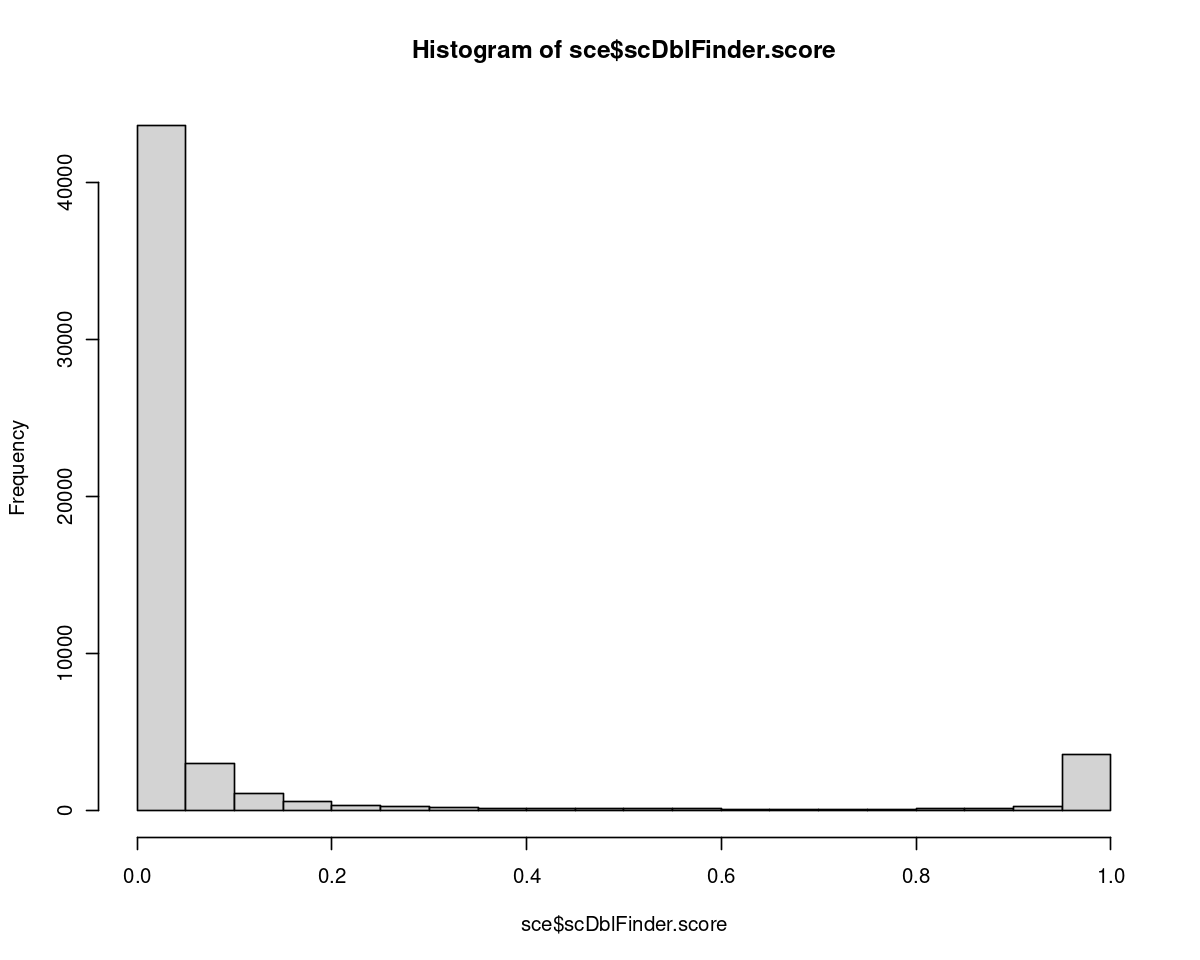

In [12]:
hist(sce$scDblFinder.score)

In [20]:
saveRDS(sce@colData, "../output/rna_meta_doublet_detected.RDS")

In [7]:
# Explore results and add to seurat object
meta_scdblfinder <- sce@colData@listData %>% as.data.frame() %>% 
  dplyr::select(starts_with('scDblFinder')) # 'scDblFinder.class')
head(meta_scdblfinder)
rownames(meta_scdblfinder) <- sce@colData@rownames
head(meta_scdblfinder)
seu <- AddMetaData(object = seu, metadata = meta_scdblfinder %>% dplyr::select('scDblFinder.class'))

,scDblFinder.sample,scDblFinder.class,scDblFinder.score,scDblFinder.weighted,scDblFinder.cxds_score
,<fct>,<fct>,<dbl>,<dbl>,<dbl>
1,lungs_2,doublet,0.9974652529,0.7009709,0.05083432966289058
2,lungs_2,singlet,0.0184364896,0.1250810,0.32651966618648842
3,lungs_2,singlet,0.0110418508,0.3356254,0.00577818725151866
4,lungs_2,doublet,0.9804773331,0.6366980,0.65183819459248105
5,lungs_2,singlet,0.0004958083,0.0000000,0.00000000006813678
6,lungs_2,singlet,0.0078478651,0.2477795,0.32709557860115857


,scDblFinder.sample,scDblFinder.class,scDblFinder.score,scDblFinder.weighted,scDblFinder.cxds_score
,<fct>,<fct>,<dbl>,<dbl>,<dbl>
AAACAGCCAACAACAA-2_1,lungs_2,doublet,0.9974652529,0.7009709,0.05083432966289058
AAACAGCCACAGCCTG-2_1,lungs_2,singlet,0.0184364896,0.1250810,0.32651966618648842
AAACAGCCAGGATGGC-2_1,lungs_2,singlet,0.0110418508,0.3356254,0.00577818725151866
AAACAGCCATCAGTAT-2_1,lungs_2,doublet,0.9804773331,0.6366980,0.65183819459248105
AAACAGCCATGAAGTA-2_1,lungs_2,singlet,0.0004958083,0.0000000,0.00000000006813678
AAACAGCCATTAAACC-2_1,lungs_2,singlet,0.0078478651,0.2477795,0.32709557860115857


In [12]:
head(seu@meta.data)
table(seu$scDblFinder.class)
rm(list = c('meta_scdblfinder', 'sce'))

,orig.ident,nCount_RNA,nFeature_RNA,percent.mt,nCount_ATAC,nFeature_ATAC,integrated_snn_res.0.5,seurat_clusters,immune_low,lung_atlas,tissue.ident,full.ident,nCount_peaks,nFeature_peaks,majority_voting,merged,scDblFinder.class
,<chr>,<dbl>,<int>,<dbl>,<dbl>,<int>,<fct>,<fct>,<chr>,<chr>,<chr>,<chr>,<dbl>,<int>,<chr>,<chr>,<fct>
AAACAGCCAACAACAA-2_1,2,4891,2351,1.819669,20272,8234,8,8,Memory B cells,B cells,lungs,lungs_2,11791,8456,Memory B cells,Memory B cells,doublet
AAACAGCCACAGCCTG-2_1,2,2106,1225,4.415954,7866,3694,1,1,CD16+ NK cells,NK cells,lungs,lungs_2,4511,3829,CD16+ NK cells,CD16+ NK cells,singlet
AAACAGCCAGGATGGC-2_1,2,2503,1303,3.995206,8074,3733,0,0,Tcm/Naive helper T cells,CD4 T cells,lungs,lungs_2,4668,3890,Tcm/Naive helper T cells,T cells,singlet
AAACAGCCATCAGTAT-2_1,2,3573,1591,4.114190,19628,8126,0,0,Tcm/Naive helper T cells,CD4 T cells,lungs,lungs_2,11343,8194,Tcm/Naive helper T cells,T cells,doublet
AAACAGCCATGAAGTA-2_1,2,6324,2584,1.391524,856,451,2,2,Tem/Trm cytotoxic T cells,CD8 T cells,lungs,lungs_2,485,478,Tem/Trm cytotoxic T cells,T cells,singlet
AAACAGCCATTAAACC-2_1,2,3075,1388,4.715447,10015,4639,7,7,Type 17 helper T cells,CD4 T cells,lungs,lungs_2,5740,4795,Type 17 helper T cells,T cells,singlet



singlet doublet 
  49220    4427 

The default behaviour of split.by has changed.
Separate violin plots are now plotted side-by-side.
To restore the old behaviour of a single split violin,
set split.plot = TRUE.
      
This message will be shown once per session.



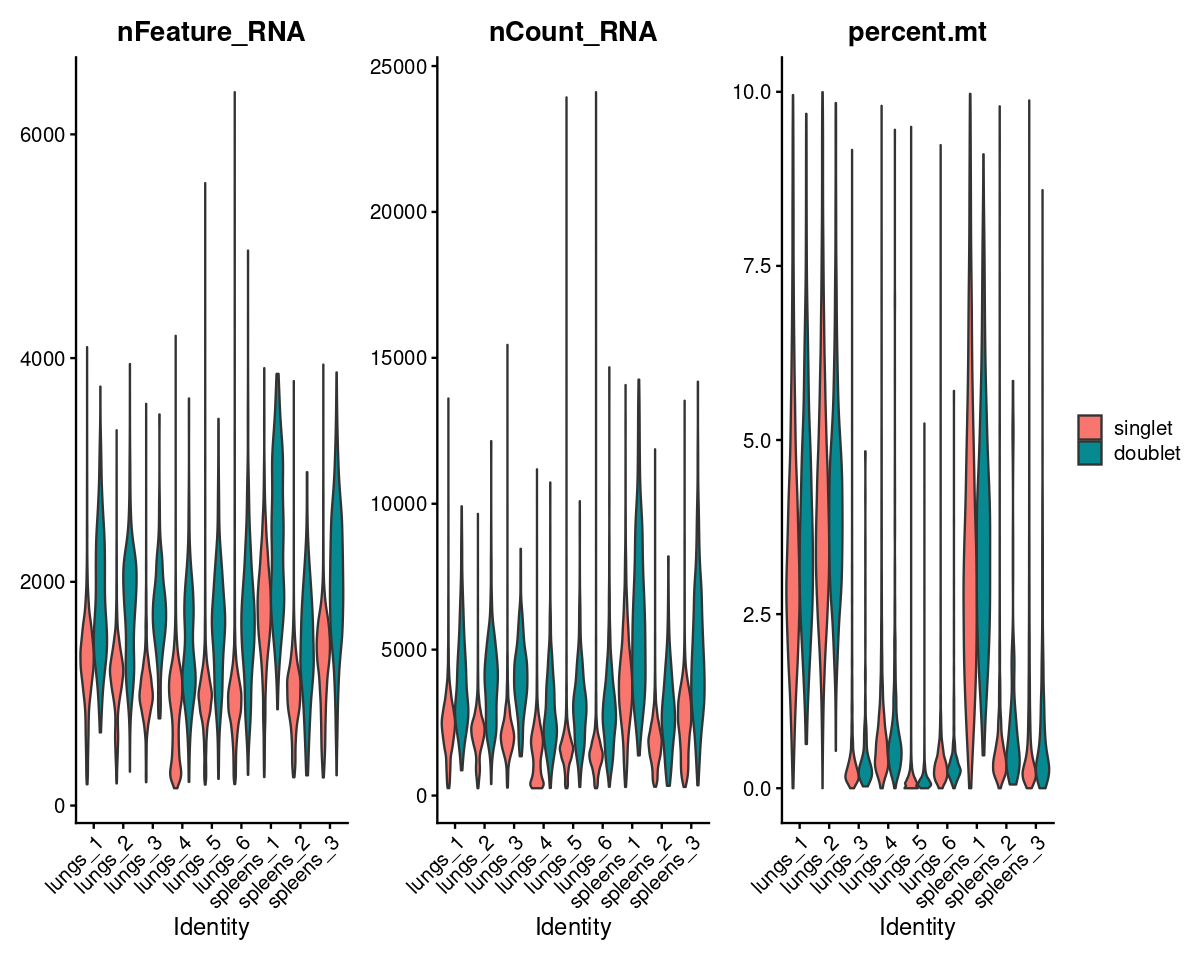

In [8]:
# Doublet stats
# Check how doublets singlets differ in QC measures per sample.
VlnPlot(seu, group.by = 'full.ident', split.by = "scDblFinder.class",
        features = c("nFeature_RNA", "nCount_RNA", "percent.mt"), 
        ncol = 3, pt.size = 0) + theme(legend.position = 'right')

In [11]:
saveRDS(seu@meta.data, "../output/rna_meta_doublet_detected.RDS")

In [7]:
subset(seu, scDblFinder.class == "singlet")

seu$PredCellType[is.na(seu$PredCellType)] <- "NA"

ifnb <- subset(seu, subset = scDblFinder.class == "singlet" & PredCellType != "NA")

ifnb

An object of class Seurat 
321136 features across 48942 samples within 4 assays 
Active assay: ATAC (149872 features, 149872 variable features)
 2 layers present: counts, data
 3 other assays present: RNA, integrated, peaks
 3 dimensional reductions calculated: pca, umap, lsi

An object of class Seurat 
321136 features across 45820 samples within 4 assays 
Active assay: ATAC (149872 features, 149872 variable features)
 2 layers present: counts, data
 3 other assays present: RNA, integrated, peaks
 3 dimensional reductions calculated: pca, umap, lsi

In [12]:
# split the dataset into a list of two seurat objects (stim and CTRL)
ifnb.list <- SplitObject(ifnb, split.by = "tissue.ident")

# normalize and identify variable features for each dataset independently
ifnb.list <- lapply(X = ifnb.list, FUN = function(x) {
    x <- NormalizeData(x)
    x <- FindVariableFeatures(x, selection.method = "vst", nfeatures = 2000)
})

# select features that are repeatedly variable across datasets for integration run PCA on each
# dataset using these features
features <- SelectIntegrationFeatures(object.list = ifnb.list)
ifnb.list <- lapply(X = ifnb.list, FUN = function(x) {
    x <- ScaleData(x, features = features, verbose = FALSE)
    x <- RunPCA(x, features = features, verbose = FALSE)
})

Warning message:
“Number of dimensions changing from 30 to 50”
Warning message:
“Number of dimensions changing from 30 to 50”


In [13]:
immune.anchors <- FindIntegrationAnchors(object.list = ifnb.list, anchor.features = features, reduction = "rpca")

Scaling features for provided objects

Computing within dataset neighborhoods

Finding all pairwise anchors

Warning message:
“Layer counts isn't present in the assay object; returning NULL”
Warning message:
“Layer counts isn't present in the assay object; returning NULL”
Warning message:
“No filtering performed if passing to data rather than counts”
Projecting new data onto SVD

Projecting new data onto SVD

Finding neighborhoods

Finding anchors

	Found 1669 anchors



In [14]:
# this command creates an 'integrated' data assay
immune.combined <- IntegrateData(anchorset = immune.anchors)

Warning message:
“Layer counts isn't present in the assay object; returning NULL”
Warning message:
“Layer counts isn't present in the assay object; returning NULL”
Merging dataset 2 into 1

Warning message:
“No filtering performed if passing to data rather than counts”
Extracting anchors for merged samples

Warning message:
“No filtering performed if passing to data rather than counts”
Finding integration vectors

Finding integration vector weights

Integrating data

Warning message:
“Layer counts isn't present in the assay object; returning NULL”
Warning message:
“Layer counts isn't present in the assay object; returning NULL”
Warning message:
“Layer counts isn't present in the assay object; returning NULL”


In [15]:
immune.combined@assays$integrated

Assay data with 2000 features for 48942 cells
Top 10 variable features:
 chr1-633583-634504, chr21-8230226-8231147, chr5-912145-913109,
chr2-148881317-148882210, chr17-22520952-22521856,
chr6-146543219-146544133, chr21-31354421-31355368,
chr4-23333590-23334644, chr3-93470145-93471058, chr1-628923-630384 

In [16]:
immune.combined <- ScaleData(immune.combined, verbose = FALSE)
immune.combined <- RunPCA(immune.combined, npcs = 30, verbose = FALSE)
immune.combined <- RunUMAP(immune.combined, reduction = "pca", dims = 1:30)
immune.combined <- FindNeighbors(immune.combined, reduction = "pca", dims = 1:30)
immune.combined <- FindClusters(immune.combined, resolution = 0.5)

Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”
22:31:25 UMAP embedding parameters a = 0.9922 b = 1.112

22:31:25 Read 48942 rows and found 30 numeric columns

22:31:25 Using Annoy for neighbor search, n_neighbors = 30

22:31:26 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

22:31:32 Writing NN index file to temp file /tmp/jobs/48608659/RtmpSgkj0C/file4331376f8175

22:31:33 Searching Annoy index using 1 thread, search_k = 3000

22:31:52 Annoy recall = 99.87%

22:31:53 Commencing smooth kNN distance calibration using 1 thread
 with tar

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 48942
Number of edges: 1402772

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8834
Number of communities: 15
Elapsed time: 12 seconds


1 singletons identified. 14 final clusters.



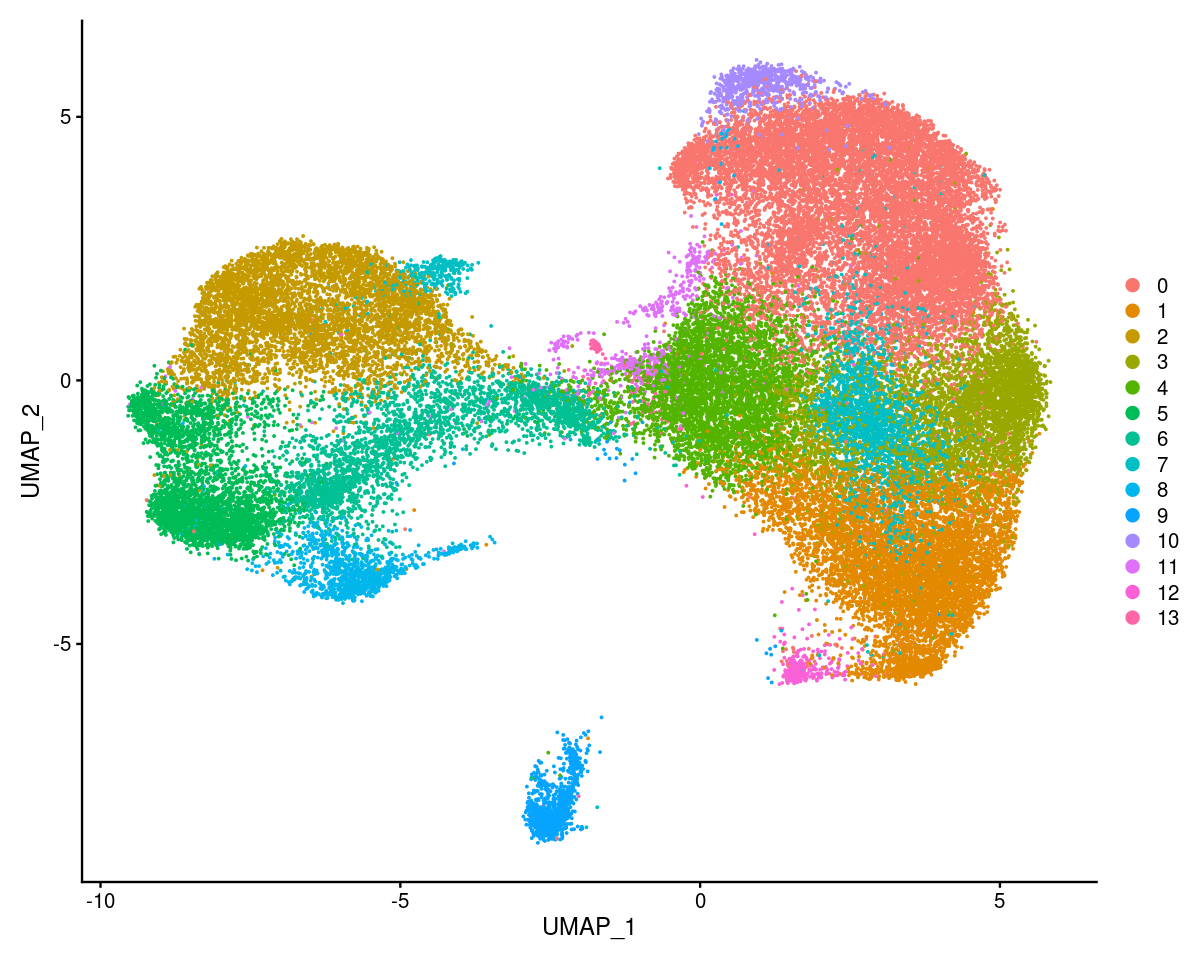

In [17]:
DimPlot(immune.combined, reduction = "umap")

In [15]:
DefaultAssay(ifnb) <- "RNA"
ifnb@active.assay

[1] "RNA"

In [16]:
## Integrate multiple lung samples
lung.list <- SplitObject(subset(ifnb, tissue.ident == "lungs"), split.by = "orig.ident")
lung.list <- lapply(X = lung.list, FUN = function(x) {
    x <- NormalizeData(x, verbose = FALSE)
    x <- FindVariableFeatures(x, verbose = FALSE)
})

features <- SelectIntegrationFeatures(object.list = lung.list)
lung.list <- lapply(X = lung.list, FUN = function(x) {
    x <- ScaleData(x, features = features, verbose = FALSE)
    x <- RunPCA(x, features = features, verbose = FALSE)
})

anchors <- FindIntegrationAnchors(object.list = lung.list, reference = c(1, 2), reduction = "rpca",
    dims = 1:20)
lung.integrated <- IntegrateData(anchorset = anchors, dims = 1:20)

lung.integrated <- ScaleData(lung.integrated, verbose = FALSE)
lung.integrated <- RunPCA(lung.integrated, verbose = FALSE)
lung.integrated <- RunUMAP(lung.integrated, dims = 1:20)

lung.integrated <- FindNeighbors(lung.integrated, reduction = "pca", dims = 1:20)
lung.integrated <- FindClusters(lung.integrated, resolution = 0.5)


Warning message:
“Number of dimensions changing from 30 to 50”
Warning message:
“Number of dimensions changing from 30 to 50”
Warning message:
“Number of dimensions changing from 30 to 50”
Warning message:
“Number of dimensions changing from 30 to 50”
Warning message:
“Number of dimensions changing from 30 to 50”
Warning message:
“Number of dimensions changing from 30 to 50”
Computing 2000 integration features

Scaling features for provided objects

Computing within dataset neighborhoods

Finding anchors between all query and reference datasets

Warning message:
“Layer counts isn't present in the assay object; returning NULL”
Warning message:
“Layer counts isn't present in the assay object; returning NULL”
Projecting new data onto SVD

Projecting new data onto SVD

Finding neighborhoods

Finding anchors

	Found 3266 anchors

Warning message:
“Layer counts isn't present in the assay object; returning NULL”
Warning message:
“Layer counts isn't present in the assay object; returning NULL”

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 33898
Number of edges: 1114216

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8951
Number of communities: 14
Elapsed time: 7 seconds


In [18]:
saveRDS(lung.integrated, "/home/jinggu/cluster/projects/u19_multiomics/analyses/remove_dup/lungs_integrated.RDS")

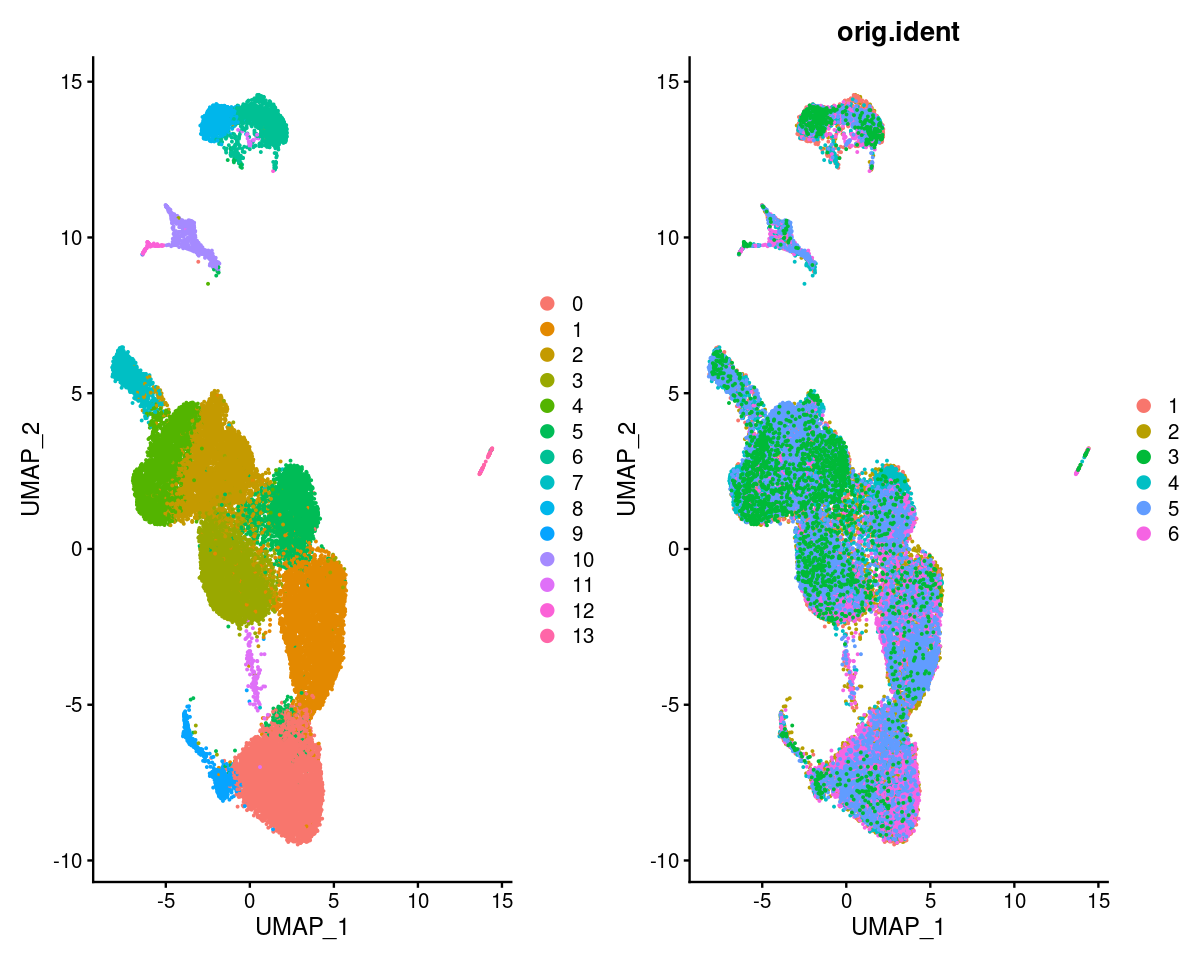

In [25]:
DimPlot(lung.integrated, reduction = "umap") + 
DimPlot(lung.integrated, reduction = "umap", group.by = "orig.ident")

In [ ]:
## Save Seurat object into a h5Dad object that can be read by scanpy package
lung.integrated <- "/home/jinggu/cluster/projects/u19_multiomics/analyses/remove_dup/lungs_integrated.RDS"
DefaultAssay(immune.combined)<-"RNA"

library("SeuratDisk")
SaveH5Seurat(immune.combined, 
             filename = "lungs_spleens_merged_scRNA_only.h5Seurat")
Convert("lungs_spleens_merged_scRNA_only.h5Seurat", dest = "h5ad")

In [21]:
pbmc.markers <- FindAllMarkers(lung.integrated, only.pos = TRUE)
pbmc.markers %>%
    group_by(cluster) %>%
    dplyr::filter(avg_log2FC > 1) %>%
    #dplyr::filter(!grepl("AC", gene)) %>%
    slice_head(n = 5) %>%
    ungroup() -> top3

Calculating cluster 0

Calculating cluster 1

Calculating cluster 2

Calculating cluster 3

Calculating cluster 4

Calculating cluster 5

Calculating cluster 6

Calculating cluster 7

Calculating cluster 8

Calculating cluster 9

Calculating cluster 10

Calculating cluster 11

Calculating cluster 12

Calculating cluster 13



ERROR: Error in pdf("output/Heatmap_marker_GE_removeDup.pdf"): cannot open file 'output/Heatmap_marker_GE_removeDup.pdf'


In [23]:
pdf("../output/Heatmap_marker_GE_removeDup.pdf")
DoHeatmap(lung.integrated, features = top3$gene) + NoLegend()
dev.off()

pdf 
  2

In [26]:
## Integrate multiple spleen samples
spleen.list <- SplitObject(subset(ifnb, tissue.ident == "spleens"), split.by = "orig.ident")
spleen.list <- lapply(X = spleen.list, FUN = function(x) {
    x <- NormalizeData(x, verbose = FALSE)
    x <- FindVariableFeatures(x, verbose = FALSE)
})

features <- SelectIntegrationFeatures(object.list = spleen.list)
spleen.list <- lapply(X = spleen.list, FUN = function(x) {
    x <- ScaleData(x, features = features, verbose = FALSE)
    x <- RunPCA(x, features = features, verbose = FALSE)
})

anchors <- FindIntegrationAnchors(object.list = spleen.list, reduction = "rpca",
    dims = 1:20)
spleen.integrated <- IntegrateData(anchorset = anchors, dims = 1:20)

spleen.integrated <- ScaleData(spleen.integrated, verbose = FALSE)
spleen.integrated <- RunPCA(spleen.integrated, verbose = FALSE)
spleen.integrated <- RunUMAP(spleen.integrated, dims = 1:20)

spleen.integrated <- FindNeighbors(spleen.integrated, reduction = "pca", dims = 1:20)
spleen.integrated <- FindClusters(spleen.integrated, resolution = 0.5)


Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“pseudoinverse used at -3.0443”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“neighborhood radius 0.30103”
Warning message in simpleLoess(y, x, w, span, degree = degree, parametric = parametric, :
“reciprocal condition number  9.0128e-16”
Warning message:
“Number of dimensions changing from 30 to 50”
Warning message:
“Number of dimensions changing from 30 to 50”
Warning message:
“Number of dimensions changing from 30 to 50”
Computing 2000 integration features

Scaling features for provided objects

Computing within dataset neighborhoods

Finding anchors between all query and reference datasets

Warning message:
“Layer counts isn't present in the assay object; returning NULL”
Warning message:
“Layer counts isn't present in the assay object; returning NULL”
Projecting new data onto SVD

Projecting new data onto SVD

Finding neighborhoods

Finding anchors


Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 11922
Number of edges: 401763

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.8636
Number of communities: 13
Elapsed time: 1 seconds


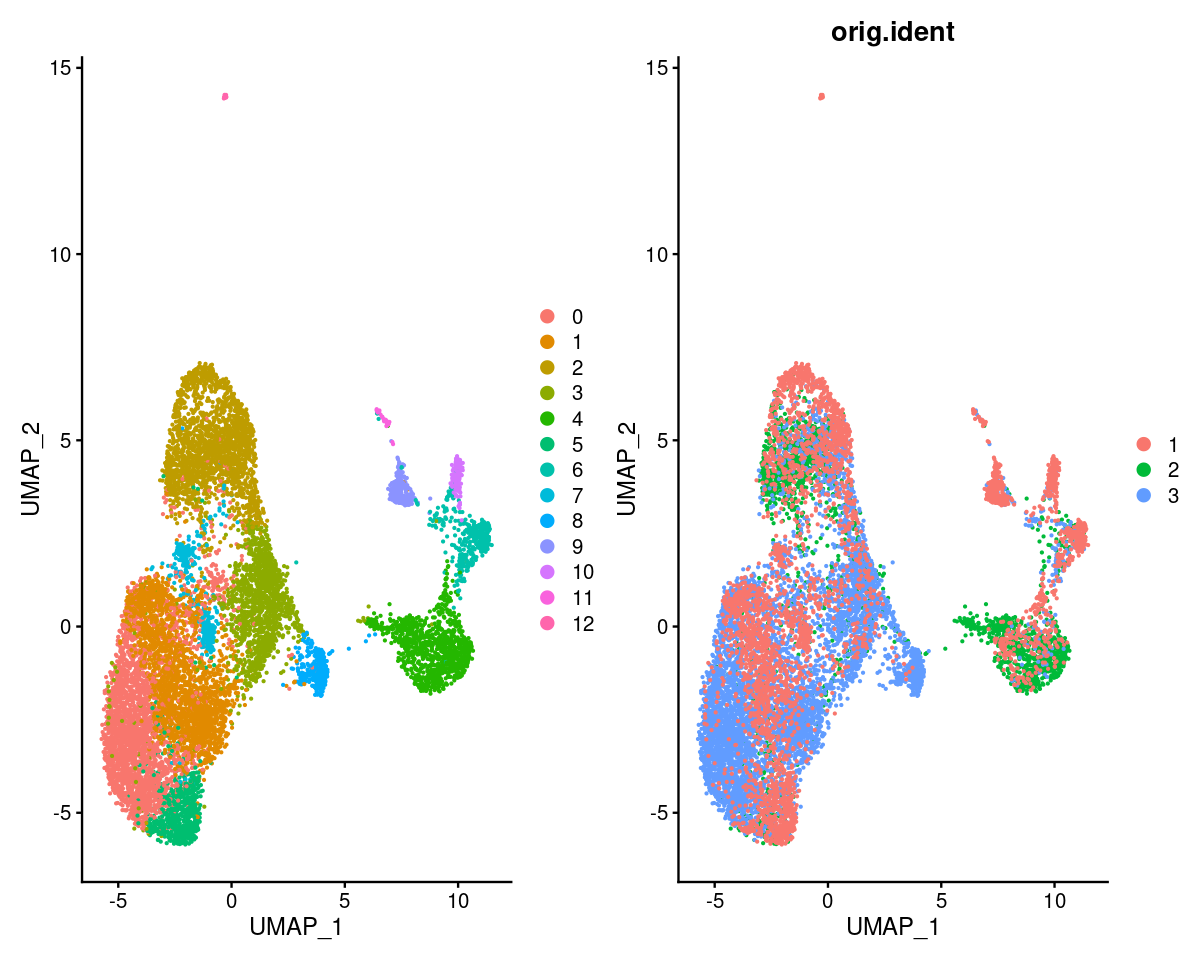

In [27]:
DimPlot(spleen.integrated, reduction = "umap") + 
DimPlot(spleen.integrated, reduction = "umap", group.by = "orig.ident")

In [28]:
saveRDS(spleen.integrated, "~/cluster/projects/u19_multiomics/analyses/remove_dup/spleens_integrated.RDS")

In [14]:
DefaultAssay(ifnb) <- "ATAC"
atac.list <- SplitObject(ifnb, split.by = "full.ident")
atac.list <- lapply(X = atac.list, FUN = function(x) {
    x <- RunTFIDF(x)
    x <- FindTopFeatures(x, min.cutoff = 'q0')
    x <- RunSVD(x)
    x <- RunUMAP(x, reduction = 'lsi', dims = 2:50, reduction.name = "umap.atac", reduction.key = "atacUMAP_")
})

Performing TF-IDF normalization

Warning message in RunTFIDF.default(object = GetAssayData(object = object, layer = "counts"), :
“Some features contain 0 total counts”
Running SVD

Scaling cell embeddings

16:32:39 UMAP embedding parameters a = 0.9922 b = 1.112

16:32:39 Read 8141 rows and found 49 numeric columns

16:32:39 Using Annoy for neighbor search, n_neighbors = 30

16:32:39 Building Annoy index with metric = cosine, n_trees = 50

0%   10   20   30   40   50   60   70   80   90   100%

[----|----|----|----|----|----|----|----|----|----|

*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
*
|

16:32:40 Writing NN index file to temp file /tmp/jobs/48616957/RtmpAHr2nk/file3d4120f671b4

16:32:40 Searching Annoy index using 1 thread, search_k = 3000

16:32:42 Annoy recall = 100%

16:32:44 Commencing smooth kNN distance calibration using 1 thread
 with target n_neighbors = 30

16:32:47 Initializing from normalized Laplacian + noise (usin

In [ ]:
anchors <- FindIntegrationAnchors(object.list = atac.list, reduction = "rpca", dims = 1:20)

Computing 2000 integration features



In [13]:
anchors <- FindIntegrationAnchors(object.list = atac.list, reduction = "rpca", dims = 1:20)
atac.integrated <- IntegrateData(anchorset = anchors, dims = 1:20)

atac.integrated <- ScaleData(atac.integrated, verbose = FALSE)
atac.integrated <- RunPCA(atac.integrated, verbose = FALSE)
atac.integrated <- RunUMAP(atac.integrated, dims = 1:20)

atac.integrated <- FindNeighbors(atac.integrated, reduction = "pca", dims = 1:20)
atac.integrated <- FindClusters(atac.integrated, resolution = 0.5)

An object of class Seurat 
321136 features across 45820 samples within 4 assays 
Active assay: ATAC (149872 features, 149872 variable features)
 2 layers present: counts, data
 3 other assays present: RNA, integrated, peaks
 3 dimensional reductions calculated: pca, umap, lsi

In [ ]:
saveRDS(atac.integrated, "../output/output_dir/remove_dup/lungs_spleens_atac_integrated.RDS")

In [6]:
features <- SelectIntegrationFeatures(object.list = list(lung.integrated, spleen.integrated))

immune.anchors <- FindIntegrationAnchors(object.list = list(lung.integrated, spleen.integrated), 
                                         anchor.features = features, reduction = "rpca")

immune.combined <- IntegrateData(anchorset = immune.anchors)

# specify that we will perform downstream analysis on the corrected data note that the
# original unmodified data still resides in the 'RNA' assay
DefaultAssay(immune.combined) <- "integrated"

# Run the standard workflow for visualization and clustering
immune.combined <- ScaleData(immune.combined, verbose = FALSE)
immune.combined <- RunPCA(immune.combined, npcs = 30, verbose = FALSE)
immune.combined <- RunUMAP(immune.combined, reduction = "pca", dims = 1:30)
immune.combined <- FindNeighbors(immune.combined, reduction = "pca", dims = 1:30)
immune.combined <- FindClusters(immune.combined, resolution = 0.5)

Scaling features for provided objects

Computing within dataset neighborhoods

Finding all pairwise anchors

Projecting new data onto SVD

Projecting new data onto SVD

Finding neighborhoods

Finding anchors

	Found 1284 anchors

Merging dataset 2 into 1

Extracting anchors for merged samples

Finding integration vectors

Finding integration vector weights

Integrating data

Warning message:
“Layer counts isn't present in the assay object; returning NULL”
Warning message:
“Layer counts isn't present in the assay object; returning NULL”
Warning message:
“Layer counts isn't present in the assay object; returning NULL”
Warning message:
“The default method for RunUMAP has changed from calling Python UMAP via reticulate to the R-native UWOT using the cosine metric
To use Python UMAP via reticulate, set umap.method to 'umap-learn' and metric to 'correlation'
This message will be shown once per session”
12:16:45 UMAP embedding parameters a = 0.9922 b = 1.112

12:16:45 Read 45820 rows and foun

Modularity Optimizer version 1.3.0 by Ludo Waltman and Nees Jan van Eck

Number of nodes: 45820
Number of edges: 1565673

Running Louvain algorithm...
Maximum modularity in 10 random starts: 0.9018
Number of communities: 17
Elapsed time: 13 seconds


1 singletons identified. 16 final clusters.



In [ ]:
## Save Seurat object into a h5Dad object that can be read by scanpy package
DefaultAssay(ifnb)<-"RNA"

library("SeuratDisk")
SaveH5Seurat(ifnb, 
             filename = "~/cluster/projects/u19_multiomics/analyses/remove_dup/lungs_spleens_scRNA_only.h5Seurat")
Convert("~/cluster/projects/u19_multiomics/analyses/remove_dup/lungs_spleens_merged_scRNA_only.h5Seurat", dest = "h5ad")

In [5]:
lung.integrated <- readRDS("../output/output_dir/remove_dup/lungs_integrated.RDS")
spleen.integrated <- readRDS("../output/output_dir/remove_dup/spleens_integrated.RDS")

In [ ]:
saveRDS(immune.combined, "../output/output_dir/remove_dup/lungs_spleens_integrated.RDS")

### WNN on one multiome dataset

In [10]:
rna.integrated <- readRDS("../output/output_dir/remove_dup/lungs_spleens_integrated.RDS")
atac.integrated <- readRDS("../output/output_dir/remove_dup/lungs_spleens_atac_integrated.RDS")

An object of class Seurat 
321136 features across 45820 samples within 4 assays 
Active assay: ATAC (149872 features, 149872 variable features)
 2 layers present: counts, data
 3 other assays present: RNA, integrated, peaks
 3 dimensional reductions calculated: pca, umap, lsi

In [ ]:
pbmc <- FindMultiModalNeighbors(pbmc, reduction.list = list("pca", "lsi"), dims.list = list(1:50, 2:50))
pbmc <- RunUMAP(pbmc, nn.name = "weighted.nn", reduction.name = "wnn.umap", reduction.key = "wnnUMAP_")
pbmc <- FindClusters(pbmc, graph.name = "wsnn", algorithm = 3, verbose = FALSE)